# Sports Edge Lab: an engineering review

This notebook has two distinct evidence sources: an executable synthetic ML example and a sanitized aggregate export from real owner runs. Synthetic training does not reproduce the private football scores.

[Project overview](../README.md) · [Model card](../docs/MODEL_CARD_CURRENT.md) · [Reproduction instructions](../examples/review_lab/README.md)

The review follows chronology, matched scoring, failure behavior, recovery and the limits of current research evidence.

In [1]:
from pathlib import Path
import json, sys, tempfile
from IPython.display import HTML, SVG, display

root = Path.cwd().resolve()
while not (root / "examples/review_lab/core.py").exists():
    if root == root.parent:
        raise RuntimeError("Run this notebook from the repository")
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from examples.review_lab.core import run_synthetic, synthetic_events, validate_rows, write_run
print({"project": "Sports Edge Lab", "python": sys.version.split()[0], "training_data": "synthetic"})

{'project': 'Sports Edge Lab', 'python': '3.12.14', 'training_data': 'synthetic'}


## 1. Fit on the past, evaluate the future

The example generates invented events with a learnable interaction. Two fixed logistic models fit the first 240 events; all three forecast systems are scored on the same 80 later events. This is an educational mechanism demonstration, not evidence that a particular football feature works.

In [2]:
synthetic = run_synthetic()
assert synthetic["data_kind"] == "synthetic"
assert not synthetic["real_football_performance"]
print(json.dumps({"training_rows": synthetic["training_rows"], "evaluation_rows": synthetic["evaluation_rows"], "scores": synthetic["scores"]}, indent=2))

{
  "training_rows": 240,
  "evaluation_rows": 80,
  "scores": {
    "MARKET_synthetic": {
      "games": 80,
      "log_loss": 0.7270739435856365,
      "brier": 0.26094180912467435,
      "accuracy": 0.575,
      "cohort_sha256": "c6a559a4fd866885d1a0691bada9a3a29732272acd01d433a36bff6795c1e246"
    },
    "additive": {
      "games": 80,
      "log_loss": 0.6733032443977589,
      "brier": 0.2396667073818856,
      "accuracy": 0.5875,
      "cohort_sha256": "c6a559a4fd866885d1a0691bada9a3a29732272acd01d433a36bff6795c1e246"
    },
    "joint": {
      "games": 80,
      "log_loss": 0.6725218345215374,
      "brier": 0.2392005590152248,
      "accuracy": 0.625,
      "cohort_sha256": "c6a559a4fd866885d1a0691bada9a3a29732272acd01d433a36bff6795c1e246"
    }
  }
}


## 2. Make invalid histories fail

This deliberately changes a feature's observation time to the event itself. Admission must reject it. The source row is synthetic and the original example remains unchanged.

In [3]:
invalid = synthetic_events(40)
invalid[0]["features_observed_at"] = invalid[0]["event_at"]
try:
    validate_rows(invalid)
except ValueError as error:
    print("EXPECTED REJECTION:", str(error))
else:
    raise AssertionError("Future information was admitted")

EXPECTED REJECTION: information-time contract violated


## 3. Reuse accepted work without another fit

The first invocation writes a report and digest manifest. The second verifies the artifact and reuses it. Incompatible configurations and corrupt files are covered by the unit tests.

In [4]:
with tempfile.TemporaryDirectory() as directory:
    output = Path(directory) / "accepted"
    first = write_run(output)
    second = write_run(output)
    assert first["new_fits"] == 2 and second["new_fits"] == 0
    assert first["report_sha256"] == second["report_sha256"]
    print({"first_status": first["status"], "second_status": second["status"], "second_new_fits": second["new_fits"], "same_artifact": True})

{'first_status': 'CREATED', 'second_status': 'REUSED', 'second_new_fits': 0, 'same_artifact': True}


## 4. Inspect real-run aggregates separately

The following table comes from the committed public evidence export. No model is fitted to these aggregates. Current monitoring ends October 15, 2026; retained references were selected on exposed results. Both latest historical challenger qualification gates failed.

In [5]:
evidence = json.loads((root / "docs/evidence/2026-10-25.json").read_text())
assert evidence["data_kind"] == "aggregate_private_run_export"
head = "<table><caption>Matched log loss; lower is better</caption><thead><tr><th>Sport / campaign</th><th>Games</th><th>MARKET</th><th>Challenger</th><th>Retained reference</th></tr></thead><tbody>"
rows = []
for row in evidence["rows"]:
    rows.append("<tr><td>{} {}</td><td>{}</td><td>{:.6f}</td><td>{:.6f}</td><td>{:.6f}</td></tr>".format(row["sport"], row["campaign"], row["games"], row["market"]["logloss"], row["challenger"]["logloss"], row["retained_log_loss_reference"]["logloss"]))
display(HTML(head + "".join(rows) + "</tbody></table>"))
print(evidence["selection_warning"])

Retained references were selected on already exposed results. These are descriptive comparisons, not untouched confirmation or proven profit.


Sport / campaign,Games,MARKET,Challenger,Retained reference
NFL 2024–2025 fixed,280,0.590011,0.585244,0.575083
NFL 2025–2026 fixed,277,0.611923,0.613622,0.606098
NFL 2025–2026 annual,277,0.611923,0.619893,0.606098
NFL 2026–2027 monitoring,77,0.660022,0.647299,0.624093
FBS 2024–2025 fixed,740,0.554096,0.555214,0.552031
FBS 2025–2026 fixed,748,0.538547,0.538406,0.536814
FBS 2025–2026 annual,748,0.538547,0.538061,0.535618
FBS 2026–2027 monitoring,301,0.474843,0.473819,0.465519


## 5. Read the current-season gap with its limits

The chart uses a zero-based log-loss scale. It compares selected retained references with MARKET, not a hypothetical profit curve. NFL has only six weekly blocks; FBS has eight. The public export contains exact metrics, policy differences and uncertainty limitations.

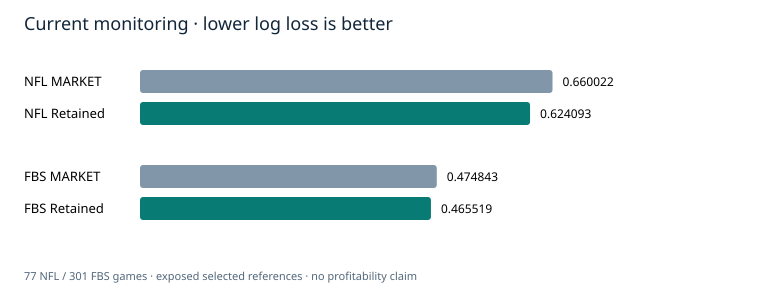

In [6]:
current = [r for r in evidence["rows"] if r["campaign"].startswith("2026")]
svg = ['<svg xmlns="http://www.w3.org/2000/svg" width="760" height="300" viewBox="0 0 760 300" role="img"><title>Selected current-season log loss against MARKET</title><rect width="760" height="300" fill="#ffffff"/><text x="24" y="30" font-family="sans-serif" font-size="18" fill="#12263a">Current monitoring · lower log loss is better</text>']
for i, row in enumerate(current):
    for j, (label, key, color) in enumerate([("MARKET", "market", "#8196a8"), ("Retained", "retained_log_loss_reference", "#087c74")]):
        value = row[key]["logloss"]
        y = 70 + i * 95 + j * 32
        width = 500 * value / 0.8
        svg.append(f'<text x="24" y="{y+16}" font-family="sans-serif" font-size="13">{row["sport"]} {label}</text><rect x="140" y="{y}" width="{width:.3f}" height="23" rx="3" fill="{color}"/><text x="{150+width:.3f}" y="{y+16}" font-family="sans-serif" font-size="12">{value:.6f}</text>')
svg.append('<text x="24" y="280" font-family="sans-serif" font-size="11" fill="#52677a">77 NFL / 301 FBS games · exposed selected references · no profitability claim</text></svg>')
display(SVG("".join(svg)))

## 6. Connect successful serving to honest abstention

V118 reused models and issued research forecasts. Stale source prices kept action admission closed. Counts of forecast rows are not counts of independent games, and an operational improvement is not a new predictive gain.

In [7]:
execution = evidence["current_execution"]
print(json.dumps({k: execution[k] for k in ["version", "tests_passed", "real_fits", "research_forecast_rows", "unique_forecast_games", "fresh_named_quotes", "paper_actions", "actual_wagers"]}, indent=2))
assert execution["actual_wagers"] == 0
print("Notebook completed. Synthetic fitting and real-run aggregates remain separate.")

{
  "version": "V118",
  "tests_passed": 927,
  "real_fits": 0,
  "research_forecast_rows": 2058,
  "unique_forecast_games": 39,
  "fresh_named_quotes": 0,
  "paper_actions": 0,
  "actual_wagers": 0
}
Notebook completed. Synthetic fitting and real-run aggregates remain separate.


## What to inspect next

- [Current evidence and uncertainty](../docs/CURRENT_EVIDENCE.md)
- [System contracts and trade-offs](../docs/SYSTEM_DESIGN.md)
- [Publication boundary](../docs/PUBLICATION_BOUNDARY.md)
- [Behavioral tests](../examples/review_lab/tests/test_core.py)

The private recipe, licensed observations, weights and individual predictions are intentionally absent. This notebook demonstrates executable engineering and clearly scoped evidence, not independent reproduction of the private model scores.